In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [6]:

data = load_breast_cancer()

df = pd.DataFrame(data.data, columns=data.feature_names)

df['target'] = data.target

print(df.head())
print("\nDataset Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum().sum())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

In [7]:
X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (455, 30)
Testing data: (114, 30)


In [8]:
dt_model = DecisionTreeClassifier(
    max_depth=4,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_predictions)

print("Decision Tree Accuracy:", dt_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, dt_predictions))

Decision Tree Accuracy: 0.9210526315789473

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.90      0.89        42
           1       0.94      0.93      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114



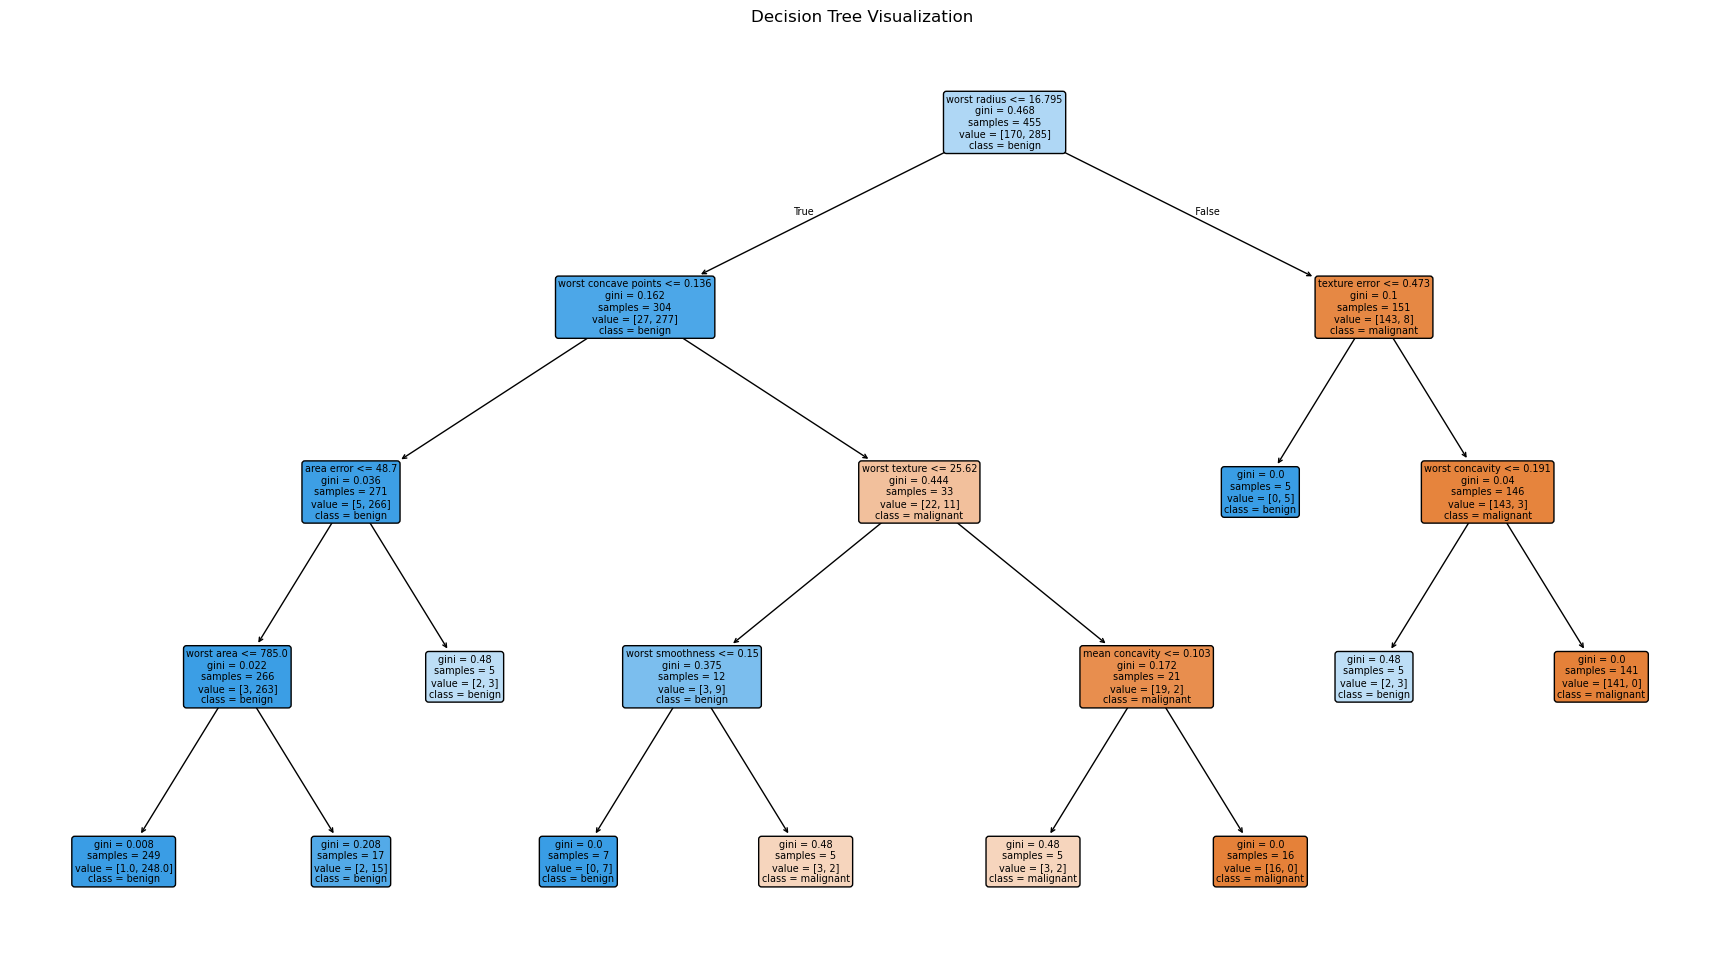

In [9]:
plt.figure(figsize=(22, 12))

plot_tree(
    dt_model,
    feature_names=data.feature_names,
    class_names=data.target_names,
    filled=True,
    rounded=True,
    fontsize=7
)

plt.title("Decision Tree Visualization")
plt.show()

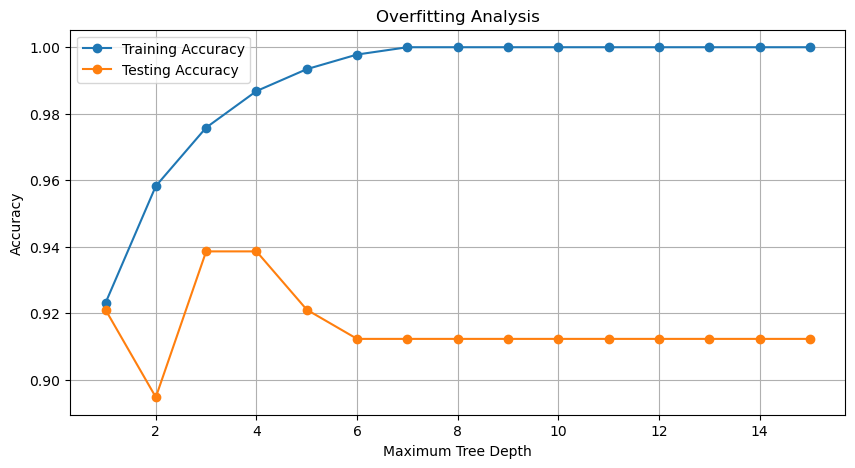

In [10]:
train_accuracy = []
test_accuracy = []
depth_values = range(1, 16)

for depth in depth_values:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_accuracy.append(
        model.score(X_train, y_train)
    )

    test_accuracy.append(
        model.score(X_test, y_test)
    )

plt.figure(figsize=(10, 5))

plt.plot(
    depth_values,
    train_accuracy,
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    depth_values,
    test_accuracy,
    marker='o',
    label='Testing Accuracy'
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Overfitting Analysis")
plt.legend()
plt.grid()
plt.show()

In [11]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    min_samples_leaf=2,
    class_weight='balanced'
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_accuracy = accuracy_score(
    y_test,
    rf_predictions
)

print("Random Forest Accuracy:", rf_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions))

Random Forest Accuracy: 0.9473684210526315

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93        42
           1       0.96      0.96      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



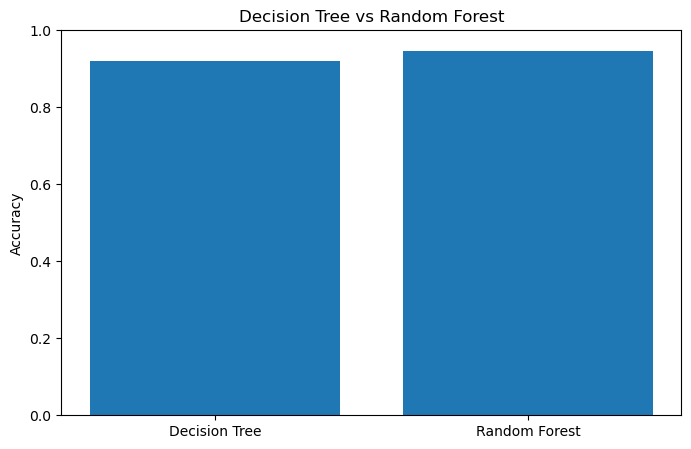

Decision Tree Accuracy: 0.9210526315789473
Random Forest Accuracy: 0.9473684210526315


In [12]:
models = ['Decision Tree', 'Random Forest']

accuracies = [
    dt_accuracy,
    rf_accuracy
]

plt.figure(figsize=(8, 5))

plt.bar(models, accuracies)

plt.ylabel("Accuracy")
plt.title("Decision Tree vs Random Forest")

plt.ylim(0, 1)
plt.show()

print("Decision Tree Accuracy:", dt_accuracy)
print("Random Forest Accuracy:", rf_accuracy)

worst perimeter         0.149087
worst area              0.140846
worst concave points    0.110894
mean concave points     0.097439
worst radius            0.084807
mean radius             0.050426
mean concavity          0.049374
worst concavity         0.043273
mean perimeter          0.042967
area error              0.039441
dtype: float64


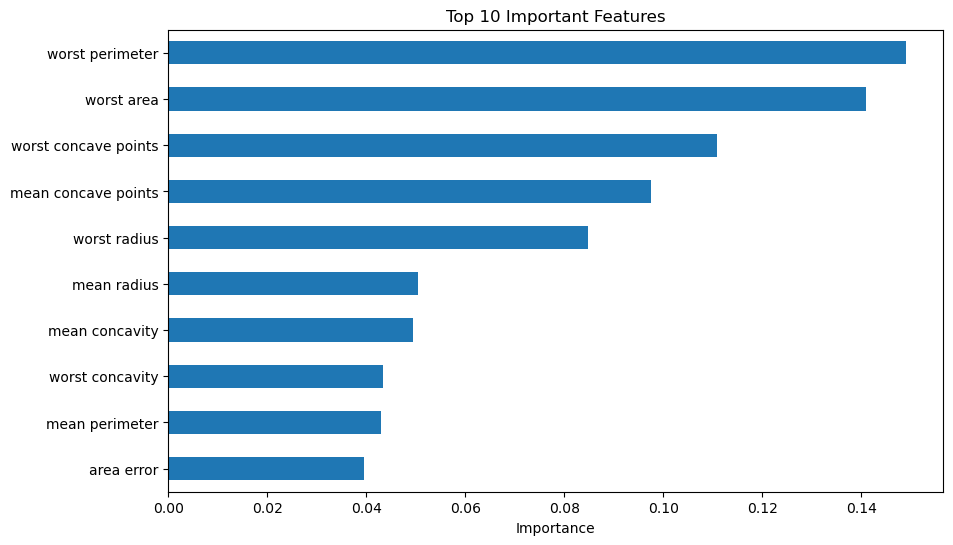

In [13]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=data.feature_names
)

feature_importance = feature_importance.sort_values(
    ascending=False
)

print(feature_importance.head(10))

plt.figure(figsize=(10, 6))

feature_importance.head(10).sort_values().plot(
    kind='barh'
)

plt.title("Top 10 Important Features")
plt.xlabel("Importance")
plt.show()

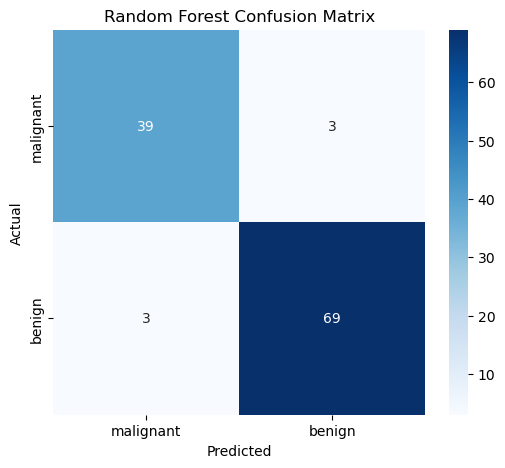

In [14]:
cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

In [15]:
dt_cv = cross_val_score(
    dt_model,
    X,
    y,
    cv=5,
    scoring='accuracy'
)

rf_cv = cross_val_score(
    rf_model,
    X,
    y,
    cv=5,
    scoring='accuracy'
)

print("Decision Tree CV Scores:", dt_cv)
print("Decision Tree Mean:", dt_cv.mean())

print("\nRandom Forest CV Scores:", rf_cv)
print("Random Forest Mean:", rf_cv.mean())

Decision Tree CV Scores: [0.92105263 0.89473684 0.95614035 0.94736842 0.92035398]
Decision Tree Mean: 0.927930445582984

Random Forest CV Scores: [0.92982456 0.95614035 0.98245614 0.95614035 0.96460177]
Random Forest Mean: 0.9578326346840551


In [16]:
results = pd.DataFrame({
    'Model': [
        'Decision Tree',
        'Random Forest'
    ],

    'Test Accuracy': [
        dt_accuracy,
        rf_accuracy
    ],

    'Cross Validation': [
        dt_cv.mean(),
        rf_cv.mean()
    ]
})

print(results)

           Model  Test Accuracy  Cross Validation
0  Decision Tree       0.921053          0.927930
1  Random Forest       0.947368          0.957833
